## 1. Import Required Libraries


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Load the Dataset

In [4]:

df = pd.read_csv("/content/Ecommerce.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (25000, 29)


,customer_id,session_id,visit_date,device_type,user_type,marketing_channel,product_id,product_category,unit_price,quantity,...,review_text,review_helpful_votes,payment_method,visit_day,visit_month,visit_weekday,visit_season,session_duration_bucket,revenue_normalized,location
0,1803,0,28-11-2024,2,1,2,894,6,651.57,1,...,1,0,1,28,11,3,0,Long,0.000000,209
1,7964,1,25-09-2024,2,0,4,844,2,945.27,4,...,1,0,2,25,9,2,0,Long,0.000000,213
2,6890,2,31-05-2024,1,1,0,865,0,400.44,4,...,1,0,2,31,5,4,1,Short,0.000000,10
3,4949,3,30-01-2024,1,0,2,851,3,1268.54,2,...,10,4,1,30,1,1,3,Very Long,0.305504,46
4,4896,4,25-02-2024,1,1,5,794,3,880.81,3,...,1,0,1,25,2,6,3,Very Short,0.000000,118


## 3. Understand the Dataset Structure

In [5]:
# Display basic dataset information

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nFirst 5 rows:")
display(df.head())

Number of rows: 25000
Number of columns: 29

Column names:
['customer_id', 'session_id', 'visit_date', 'device_type', 'user_type', 'marketing_channel', 'product_id', 'product_category', 'unit_price', 'quantity', 'discount_percent', 'discount_amount', 'revenue', 'pages_viewed', 'time_on_site_sec', 'added_to_cart', 'purchased', 'cart_abandoned', 'rating', 'review_text', 'review_helpful_votes', 'payment_method', 'visit_day', 'visit_month', 'visit_weekday', 'visit_season', 'session_duration_bucket', 'revenue_normalized', 'location']

Data types:
customer_id                  int64
session_id                   int64
visit_date                  object
device_type                  int64
user_type                    int64
marketing_channel            int64
product_id                   int64
product_category             int64
unit_price                 float64
quantity                     int64
discount_percent             int64
discount_amount            float64
revenue                    float

,customer_id,session_id,visit_date,device_type,user_type,marketing_channel,product_id,product_category,unit_price,quantity,...,review_text,review_helpful_votes,payment_method,visit_day,visit_month,visit_weekday,visit_season,session_duration_bucket,revenue_normalized,location
0,1803,0,28-11-2024,2,1,2,894,6,651.57,1,...,1,0,1,28,11,3,0,Long,0.000000,209
1,7964,1,25-09-2024,2,0,4,844,2,945.27,4,...,1,0,2,25,9,2,0,Long,0.000000,213
2,6890,2,31-05-2024,1,1,0,865,0,400.44,4,...,1,0,2,31,5,4,1,Short,0.000000,10
3,4949,3,30-01-2024,1,0,2,851,3,1268.54,2,...,10,4,1,30,1,1,3,Very Long,0.305504,46
4,4896,4,25-02-2024,1,1,5,794,3,880.81,3,...,1,0,1,25,2,6,3,Very Short,0.000000,118


## 4. Data Quality Check

In [6]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

print("\nNumber of duplicate rows:", df.duplicated().sum())

Missing values in each column:
customer_id                0
session_id                 0
visit_date                 0
device_type                0
user_type                  0
marketing_channel          0
product_id                 0
product_category           0
unit_price                 0
quantity                   0
discount_percent           0
discount_amount            0
revenue                    0
pages_viewed               0
time_on_site_sec           0
added_to_cart              0
purchased                  0
cart_abandoned             0
rating                     0
review_text                0
review_helpful_votes       0
payment_method             0
visit_day                  0
visit_month                0
visit_weekday              0
visit_season               0
session_duration_bucket    0
revenue_normalized         0
location                   0
dtype: int64

Total missing values: 0

Number of duplicate rows: 0


## 5. Identify Target Variables


In [7]:
print("Rating distribution:")
print(df["rating"].value_counts().sort_index())

print("\nPurchased distribution:")
print(df["purchased"].value_counts().sort_index())

print("\nRating statistics:")
print(df["rating"].describe())

Rating distribution:
rating
1      262
2      551
3     1110
4    21379
5     1698
Name: count, dtype: int64

Purchased distribution:
purchased
0    19384
1     5616
Name: count, dtype: int64

Rating statistics:
count    25000.00000
mean         3.94800
std          0.54047
min          1.00000
25%          4.00000
50%          4.00000
75%          4.00000
max          5.00000
Name: rating, dtype: float64


## 6. Exploratory Data Analysis

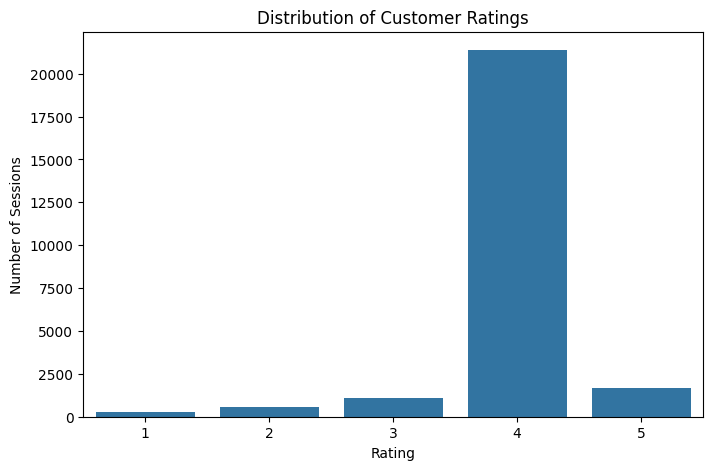

In [8]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="rating")

plt.title("Distribution of Customer Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Sessions")

plt.show()

### 6.1 Purchase Distribution

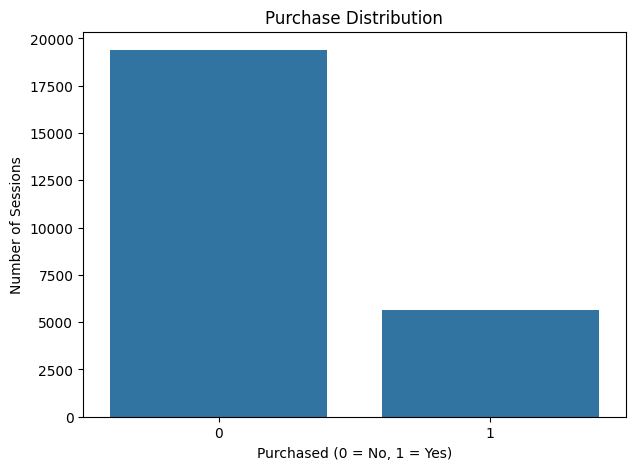

In [9]:
# Purchase distribution

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="purchased")

plt.title("Purchase Distribution")
plt.xlabel("Purchased (0 = No, 1 = Yes)")
plt.ylabel("Number of Sessions")

plt.show()

### 6.2 Purchase Rate by Marketing Channel

Purchase rate by marketing channel:
marketing_channel
0    22.717149
1    22.124105
2    22.027564
3    22.643343
4    21.659771
5    23.598405
Name: purchased, dtype: float64


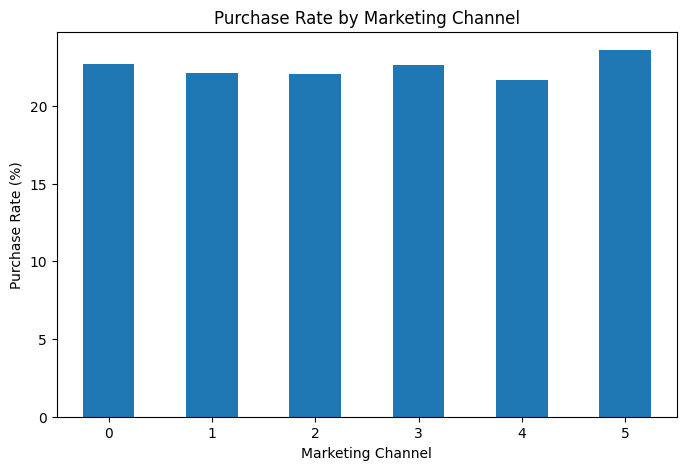

In [10]:
purchase_by_channel = df.groupby("marketing_channel")["purchased"].mean() * 100

print("Purchase rate by marketing channel:")
print(purchase_by_channel)

plt.figure(figsize=(8, 5))

purchase_by_channel.plot(kind="bar")

plt.title("Purchase Rate by Marketing Channel")
plt.xlabel("Marketing Channel")
plt.ylabel("Purchase Rate (%)")
plt.xticks(rotation=0)

plt.show()

### 6.3 Average Time on Site by Purchase Status

Average time on site:
purchased
0    895.605809
1    929.691952
Name: time_on_site_sec, dtype: float64


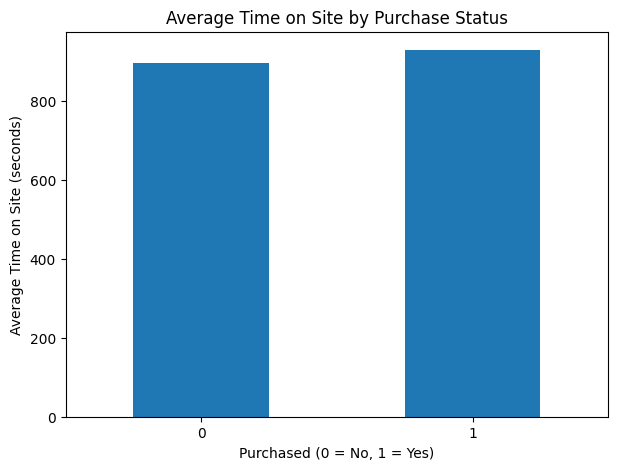

In [11]:
purchase_time = df.groupby("purchased")["time_on_site_sec"].mean()

print("Average time on site:")
print(purchase_time)

plt.figure(figsize=(7, 5))

purchase_time.plot(kind="bar")

plt.title("Average Time on Site by Purchase Status")
plt.xlabel("Purchased (0 = No, 1 = Yes)")
plt.ylabel("Average Time on Site (seconds)")
plt.xticks(rotation=0)

plt.show()

### 6.4 Average Discount by Purchase Status

Average discount by purchase status:
purchased
0    8.992210
1    9.021546
Name: discount_percent, dtype: float64


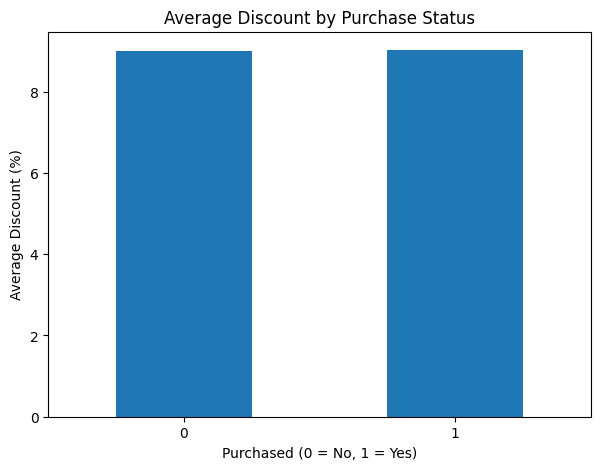

In [12]:
discount_purchase = df.groupby("purchased")["discount_percent"].mean()

print("Average discount by purchase status:")
print(discount_purchase)

plt.figure(figsize=(7, 5))

discount_purchase.plot(kind="bar")

plt.title("Average Discount by Purchase Status")
plt.xlabel("Purchased (0 = No, 1 = Yes)")
plt.ylabel("Average Discount (%)")
plt.xticks(rotation=0)

plt.show()

### 6.5 Purchase Rate by Add-to-Cart Status

Purchase rate by add-to-cart status:
added_to_cart
0     0.000000
1    34.845195
Name: purchased, dtype: float64


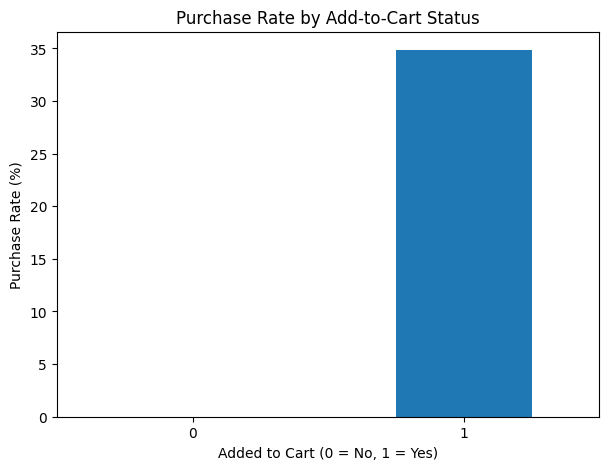

In [13]:
cart_purchase = df.groupby("added_to_cart")["purchased"].mean() * 100

print("Purchase rate by add-to-cart status:")
print(cart_purchase)

plt.figure(figsize=(7, 5))

cart_purchase.plot(kind="bar")

plt.title("Purchase Rate by Add-to-Cart Status")
plt.xlabel("Added to Cart (0 = No, 1 = Yes)")
plt.ylabel("Purchase Rate (%)")
plt.xticks(rotation=0)

plt.show()

### 6.6 Identification of Potential Data Leakage

In [14]:
leakage_columns = [
    "revenue",
    "revenue_normalized",
    "review_text",
    "review_helpful_votes",
    "cart_abandoned"
]

print("Potential leakage variables:\n")

for col in leakage_columns:
    print(f"{col}:")
    print(df.groupby("purchased")[col].mean())
    print()

Potential leakage variables:

revenue:
purchased
0       0.000000
1    1801.312155
Name: revenue, dtype: float64

revenue_normalized:
purchased
0    0.000000
1    0.228322
Name: revenue_normalized, dtype: float64

review_text:
purchased
0    1.000000
1    4.004274
Name: review_text, dtype: float64

review_helpful_votes:
purchased
0     0.000000
1    24.576211
Name: review_helpful_votes, dtype: float64

cart_abandoned:
purchased
0    0.541735
1    0.000000
Name: cart_abandoned, dtype: float64



## 7. Feature Selection

In [15]:
# Define features for the classification task

classification_features = [
    "unit_price",
    "quantity",
    "discount_percent",
    "discount_amount",
    "pages_viewed",
    "time_on_site_sec",
    "added_to_cart",
    "device_type",
    "user_type",
    "marketing_channel",
    "product_category",
    "payment_method",
    "visit_day",
    "visit_month",
    "visit_weekday",
    "visit_season",
    "session_duration_bucket",
    "location"
]

X_classification = df[classification_features].copy()
y_classification = df["purchased"].copy()

print("Classification dataset:")
print("Rows:", X_classification.shape[0])
print("Features:", X_classification.shape[1])
print("Target:", y_classification.name)

Classification dataset:
Rows: 25000
Features: 18
Target: purchased


### 7.1 Regression Feature Selection

In [16]:
purchased_df = df[df["purchased"] == 1].copy()

regression_features = classification_features.copy()

X_regression = purchased_df[regression_features].copy()
y_regression = purchased_df["rating"].copy()

print("Regression dataset:")
print("Rows:", X_regression.shape[0])
print("Features:", X_regression.shape[1])
print("Target:", y_regression.name)

print("\nRating distribution:")
print(y_regression.value_counts().sort_index())

Regression dataset:
Rows: 5616
Features: 18
Target: rating

Rating distribution:
rating
1     262
2     551
3    1110
4    1995
5    1698
Name: count, dtype: int64


## 8. Train-Test Split

In [17]:
# Train-test split for Regression

X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_regression,
    y_regression,
    test_size=0.20,
    random_state=42
)

# Train-test split for Classification

X_clf_train, X_clf_test, y_clf_train, y_clf_test = train_test_split(
    X_classification,
    y_classification,
    test_size=0.20,
    random_state=42,
    stratify=y_classification
)

print("Regression:")
print("Training set:", X_reg_train.shape)
print("Testing set :", X_reg_test.shape)

print("\nClassification:")
print("Training set:", X_clf_train.shape)
print("Testing set :", X_clf_test.shape)

Regression:
Training set: (4492, 18)
Testing set : (1124, 18)

Classification:
Training set: (20000, 18)
Testing set : (5000, 18)


## 9. Data Preprocessing


In [18]:
# Define numerical and categorical features

numeric_features = [
    "unit_price",
    "quantity",
    "discount_percent",
    "discount_amount",
    "pages_viewed",
    "time_on_site_sec",
    "added_to_cart",
    "visit_day",
    "visit_month",
    "visit_weekday"
]

categorical_features = [
    "device_type",
    "user_type",
    "marketing_channel",
    "product_category",
    "payment_method",
    "visit_season",
    "session_duration_bucket",
    "location"
]

# Create preprocessing pipeline

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")
print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Total features:", len(numeric_features) + len(categorical_features))

Preprocessing pipeline created successfully!
Numerical features: 10
Categorical features: 8
Total features: 18


## 10. Preprocess the Regression Data

In [19]:
# Fit preprocessing on regression training data
X_reg_train_processed = preprocessor.fit_transform(X_reg_train)

# Transform regression test data using the fitted preprocessor
X_reg_test_processed = preprocessor.transform(X_reg_test)

print("Regression preprocessing completed!")

print("Training data shape:", X_reg_train_processed.shape)
print("Testing data shape :", X_reg_test_processed.shape)

Regression preprocessing completed!
Training data shape: (4492, 268)
Testing data shape : (1124, 268)


## 11. Regression Model — Linear Regression

In [20]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Create and train the Linear Regression model
linear_model = LinearRegression()

linear_model.fit(X_reg_train_processed, y_reg_train)

# Predict ratings on the test set
y_reg_pred = linear_model.predict(X_reg_test_processed)

# Evaluate the model
mae = mean_absolute_error(y_reg_test, y_reg_pred)
rmse = np.sqrt(mean_squared_error(y_reg_test, y_reg_pred))
r2 = r2_score(y_reg_test, y_reg_pred)

print("Linear Regression Results")
print("-------------------------")
print("MAE :", mae)
print("RMSE:", rmse)
print("R²  :", r2)

Linear Regression Results
-------------------------
MAE : 0.9218774787080847
RMSE: 1.1415495996272051
R²  : -0.08292842931431488


## 11. Regression — Ridge Regression

In [21]:
from sklearn.linear_model import Ridge

# Create the Ridge Regression model
ridge_model = Ridge(alpha=1.0)

# Train the model
ridge_model.fit(X_reg_train_processed, y_reg_train)

# Make predictions
y_ridge_pred = ridge_model.predict(X_reg_test_processed)

# Evaluate the model
ridge_mae = mean_absolute_error(y_reg_test, y_ridge_pred)
ridge_rmse = np.sqrt(mean_squared_error(y_reg_test, y_ridge_pred))
ridge_r2 = r2_score(y_reg_test, y_ridge_pred)

print("Ridge Regression Results")
print("------------------------")
print("MAE :", ridge_mae)
print("RMSE:", ridge_rmse)
print("R²  :", ridge_r2)

Ridge Regression Results
------------------------
MAE : 0.9189307872885337
RMSE: 1.1377431903355502
R²  : -0.07571858669998655


## 12. Ridge Regression — Hyperparameter Optimization

In [22]:
from sklearn.model_selection import GridSearchCV

# Define the Ridge model
ridge = Ridge()

# Define hyperparameter values
param_grid = {
    "alpha": [0.01, 0.1, 1, 10, 100]
}

# Grid search with 5-fold cross-validation
ridge_grid = GridSearchCV(
    estimator=ridge,
    param_grid=param_grid,
    cv=5,
    scoring="neg_mean_squared_error",
    n_jobs=-1
)

# Fit GridSearchCV on training data only
ridge_grid.fit(X_reg_train_processed, y_reg_train)

print("Best alpha:", ridge_grid.best_params_["alpha"])
print("Best CV RMSE:", np.sqrt(-ridge_grid.best_score_))

Best alpha: 100
Best CV RMSE: 1.1344318795097426


## 13. Final Ridge Regression Evaluation

In [23]:
# Get the best Ridge model
best_ridge_model = ridge_grid.best_estimator_

# Predict on the test set
y_ridge_best_pred = best_ridge_model.predict(X_reg_test_processed)

# Calculate evaluation metrics
final_mae = mean_absolute_error(y_reg_test, y_ridge_best_pred)
final_rmse = np.sqrt(mean_squared_error(y_reg_test, y_ridge_best_pred))
final_r2 = r2_score(y_reg_test, y_ridge_best_pred)

print("Final Ridge Regression Results")
print("--------------------------------")
print("Best Alpha:", ridge_grid.best_params_["alpha"])
print("MAE :", final_mae)
print("RMSE:", final_rmse)
print("R²  :", final_r2)

Final Ridge Regression Results
--------------------------------
Best Alpha: 100
MAE : 0.8969678235482016
RMSE: 1.1032604553376526
R²  : -0.011500930525515818


### 14.1 Preprocess Classification Data

In [24]:
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)
# Create a separate preprocessing pipeline for classification

classification_preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

# Fit only on classification training data
X_clf_train_processed = classification_preprocessor.fit_transform(X_clf_train)

# Transform classification test data
X_clf_test_processed = classification_preprocessor.transform(X_clf_test)

print("Classification preprocessing completed!")

print("Training data shape:", X_clf_train_processed.shape)
print("Testing data shape :", X_clf_test_processed.shape)

Classification preprocessing completed!
Training data shape: (20000, 268)
Testing data shape : (5000, 268)


### 14.2 Logistic Regression Model

In [25]:
# Create the Logistic Regression model

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model
logistic_model.fit(
    X_clf_train_processed,
    y_clf_train
)

# Predict class labels
y_clf_pred = logistic_model.predict(X_clf_test_processed)

# Predict purchase probabilities
y_clf_prob = logistic_model.predict_proba(
    X_clf_test_processed
)[:, 1]

# Calculate evaluation metrics
accuracy = accuracy_score(y_clf_test, y_clf_pred)
precision = precision_score(y_clf_test, y_clf_pred)
recall = recall_score(y_clf_test, y_clf_pred)
f1 = f1_score(y_clf_test, y_clf_pred)
roc_auc = roc_auc_score(y_clf_test, y_clf_prob)

print("Logistic Regression Results")
print("---------------------------")
print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1-score :", f1)
print("ROC-AUC  :", roc_auc)

Logistic Regression Results
---------------------------
Accuracy : 0.7724
Precision: 0.4358974358974359
Recall   : 0.04541406945681211
F1-score : 0.08225806451612903
ROC-AUC  : 0.759186939622235


## 15. Logistic Regression — Hyperparameter Optimization

In [26]:
# Hyperparameter optimization for Logistic Regression

logistic = LogisticRegression(
    max_iter=1000,
    random_state=42
)

param_grid = {
    "C": [0.01, 0.1, 1, 10, 100]
}

logistic_grid = GridSearchCV(
    estimator=logistic,
    param_grid=param_grid,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1
)

# Fit only on training data
logistic_grid.fit(
    X_clf_train_processed,
    y_clf_train
)

print("Best C:", logistic_grid.best_params_["C"])
print("Best CV ROC-AUC:", logistic_grid.best_score_)

Best C: 0.01
Best CV ROC-AUC: 0.7652262007921038


## 16. Final Logistic Regression Evaluation

In [27]:
# Get the best Logistic Regression model
best_logistic_model = logistic_grid.best_estimator_

# Predict class labels
y_logistic_pred = best_logistic_model.predict(X_clf_test_processed)

# Predict probabilities for ROC-AUC
y_logistic_prob = best_logistic_model.predict_proba(
    X_clf_test_processed
)[:, 1]

# Calculate final evaluation metrics
final_accuracy = accuracy_score(y_clf_test, y_logistic_pred)
final_precision = precision_score(y_clf_test, y_logistic_pred)
final_recall = recall_score(y_clf_test, y_logistic_pred)
final_f1 = f1_score(y_clf_test, y_logistic_pred)
final_roc_auc = roc_auc_score(y_clf_test, y_logistic_prob)

print("Final Logistic Regression Results")
print("-----------------------------------")
print("Best C   :", logistic_grid.best_params_["C"])
print("Accuracy :", final_accuracy)
print("Precision:", final_precision)
print("Recall   :", final_recall)
print("F1-score :", final_f1)
print("ROC-AUC  :", final_roc_auc)

Final Logistic Regression Results
-----------------------------------
Best C   : 0.01
Accuracy : 0.7754
Precision: 0.0
Recall   : 0.0
F1-score : 0.0
ROC-AUC  : 0.7643892067541734


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


## 17. Confusion Matrix

Confusion Matrix:
[[3877    0]
 [1123    0]]


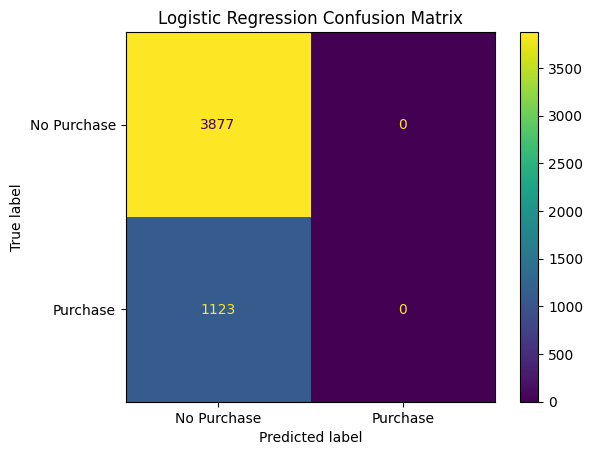

In [28]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Calculate confusion matrix
cm = confusion_matrix(y_clf_test, y_logistic_pred)

print("Confusion Matrix:")
print(cm)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Purchase", "Purchase"]
)

disp.plot()
plt.title("Logistic Regression Confusion Matrix")
plt.show()

## 18. Analysis of Predicted Probabilities


In [29]:
# Examine predicted purchase probabilities

print("Predicted probability statistics:")
print(pd.Series(y_logistic_prob).describe())

print("\nMaximum predicted probability:",
      y_logistic_prob.max())

print("\nNumber of predictions >= 0.5:",
      (y_logistic_prob >= 0.5).sum())

Predicted probability statistics:
count    5000.000000
mean        0.228209
std         0.164619
min         0.006411
25%         0.014229
50%         0.291683
75%         0.371881
max         0.485990
dtype: float64

Maximum predicted probability: 0.485990162362046

Number of predictions >= 0.5: 0


## 19. Classification Threshold Analysis

In [30]:
# Analyze different classification thresholds

thresholds = np.arange(0.05, 0.50, 0.01)

threshold_results = []

for threshold in thresholds:
    predictions = (y_logistic_prob >= threshold).astype(int)

    precision = precision_score(
        y_clf_test,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        y_clf_test,
        predictions,
        zero_division=0
    )

    f1 = f1_score(
        y_clf_test,
        predictions,
        zero_division=0
    )

    threshold_results.append(
        [threshold, precision, recall, f1]
    )

threshold_df = pd.DataFrame(
    threshold_results,
    columns=["Threshold", "Precision", "Recall", "F1"]
)

# Find threshold with highest F1
best_threshold_row = threshold_df.loc[
    threshold_df["F1"].idxmax()
]

print("Best threshold based on F1-score:")
print(best_threshold_row)

print("\nTop 10 thresholds:")
display(
    threshold_df.sort_values(
        "F1",
        ascending=False
    ).head(10)
)

Best threshold based on F1-score:
Threshold    0.290000
Precision    0.374852
Recall       0.846839
F1           0.519672
Name: 24, dtype: float64

Top 10 thresholds:


,Threshold,Precision,Recall,F1
24,0.29,0.374852,0.846839,0.519672
23,0.28,0.367506,0.884239,0.519216
22,0.27,0.360084,0.918967,0.517423
21,0.26,0.353117,0.948353,0.514617
18,0.23,0.345018,0.999110,0.512914
19,0.24,0.346010,0.988424,0.512584
20,0.25,0.347992,0.972395,0.512556
5,0.10,0.344479,1.000000,0.512434
0,0.05,0.344479,1.000000,0.512434
1,0.06,0.344479,1.000000,0.512434


In [31]:

import numpy as np
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.base import clone
from sklearn.metrics import precision_recall_curve, f1_score

# Generate out-of-fold purchase probabilities from training data
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

oof_probabilities = cross_val_predict(
    clone(best_logistic_model),
    X_clf_train_processed,
    y_classification.loc[X_clf_train.index],
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

# Find the threshold with the best training cross-validation F1-score
precision, recall, thresholds = precision_recall_curve(
    y_classification.loc[X_clf_train.index],
    oof_probabilities
)

f1_scores = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-10)
)

best_index = np.argmax(f1_scores)
best_threshold = thresholds[best_index]

print("Best threshold from training cross-validation:", round(best_threshold, 4))
print("Cross-validation Precision:", round(precision[best_index], 4))
print("Cross-validation Recall:", round(recall[best_index], 4))
print("Cross-validation F1-score:", round(f1_scores[best_index], 4))


Best threshold from training cross-validation: 0.2691
Cross-validation Precision: 0.3627
Cross-validation Recall: 0.9148
Cross-validation F1-score: 0.5194


In [32]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Predict purchase probabilities on the untouched test set
y_test = y_classification.loc[X_clf_test.index]

test_probabilities = best_logistic_model.predict_proba(
    X_clf_test_processed
)[:, 1]

# Apply the threshold selected using training cross-validation
y_test_pred_tuned = (
    test_probabilities >= best_threshold
).astype(int)

# Evaluate final test performance
print("Selected Threshold:", round(best_threshold, 4))
print("Accuracy:", round(accuracy_score(y_test, y_test_pred_tuned), 4))
print("Precision:", round(precision_score(y_test, y_test_pred_tuned, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_test_pred_tuned, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, y_test_pred_tuned, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, test_probabilities), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_tuned))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred_tuned, zero_division=0))


Selected Threshold: 0.2691
Accuracy: 0.6142
Precision: 0.3601
Recall: 0.9234
F1-score: 0.5181
ROC-AUC: 0.7644

Confusion Matrix:
[[2034 1843]
 [  86 1037]]

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.52      0.68      3877
           1       0.36      0.92      0.52      1123

    accuracy                           0.61      5000
   macro avg       0.66      0.72      0.60      5000
weighted avg       0.82      0.61      0.64      5000



In [33]:

# Check the number of customers and sessions
print("Total sessions:", len(df))
print("Unique customers:", df["customer_id"].nunique())

# Aggregate session-level data into customer-level features
customer_features = df.groupby("customer_id").agg(
    total_sessions=("session_id", "nunique"),
    purchase_rate=("purchased", "mean"),
    avg_session_duration=("time_on_site_sec", "mean"),
    avg_pages_viewed=("pages_viewed", "mean"),
    avg_unit_price=("unit_price", "mean"),
    avg_discount=("discount_percent", "mean"),
    cart_add_rate=("added_to_cart", "mean"),
    avg_quantity=("quantity", "mean"),
    total_revenue=("revenue", "sum")
).reset_index()

print("\nCustomer-level dataset shape:", customer_features.shape)
print("\nFirst five rows:")
display(customer_features.head())

print("\nMissing values:")
print(customer_features.isnull().sum())


Total sessions: 25000
Unique customers: 8442

Customer-level dataset shape: (8442, 10)

First five rows:


,customer_id,total_sessions,purchase_rate,avg_session_duration,avg_pages_viewed,avg_unit_price,avg_discount,cart_add_rate,avg_quantity,total_revenue
0,1000,2,0.500000,1014.000000,17.500000,459.960000,17.500000,1.000000,3.500000,1228.72
1,1001,1,0.000000,996.000000,15.000000,928.910000,0.000000,0.000000,4.000000,0.00
2,1002,3,0.000000,313.666667,8.333333,1025.123333,3.333333,0.666667,2.666667,0.00
3,1003,3,0.333333,695.333333,5.666667,579.600000,11.666667,0.333333,3.000000,1681.96
4,1004,3,0.000000,923.666667,12.333333,894.560000,16.666667,0.333333,1.666667,0.00



Missing values:
customer_id             0
total_sessions          0
purchase_rate           0
avg_session_duration    0
avg_pages_viewed        0
avg_unit_price          0
avg_discount            0
cart_add_rate           0
avg_quantity            0
total_revenue           0
dtype: int64



### Scaling the Features

I am scaling the customer features before applying K-Means so that features with larger values do not dominate the clustering.


In [34]:

from sklearn.preprocessing import StandardScaler

# Exclude customer_id from clustering
clustering_features = customer_features.drop(columns=["customer_id"])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(clustering_features)

print("Scaled data shape:", X_scaled.shape)
print("Mean of first 5 features:", X_scaled.mean(axis=0)[:5].round(4))
print("Standard deviation of first 5 features:", X_scaled.std(axis=0)[:5].round(4))


Scaled data shape: (8442, 9)
Mean of first 5 features: [ 0.  0. -0.  0.  0.]
Standard deviation of first 5 features: [1. 1. 1. 1. 1.]



### Finding the Optimal Number of Clusters

I am checking different values of K to find a suitable number of customer groups using the elbow method.


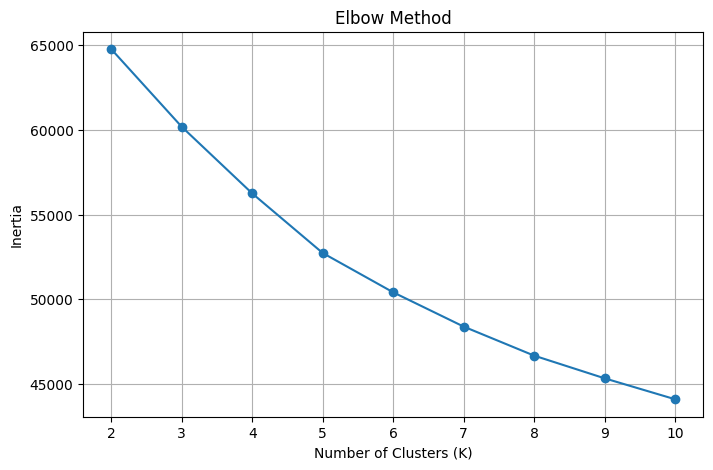

In [35]:

import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

inertias = []
k_values = range(2, 11)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        init="k-means++",
        max_iter=300,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertias, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()



### Comparing Cluster Scores

I am comparing the silhouette scores for different K values to choose the number of customer groups.


In [36]:

from sklearn.metrics import silhouette_score

for k in [3, 4, 5, 6]:
    kmeans = KMeans(
        n_clusters=k,
        init="k-means++",
        max_iter=300,
        random_state=42,
        n_init=10
    )
    labels = kmeans.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)

    print(f"K = {k}, Silhouette Score = {score:.4f}")


K = 3, Silhouette Score = 0.1216
K = 4, Silhouette Score = 0.0860
K = 5, Silhouette Score = 0.1026
K = 6, Silhouette Score = 0.1051



### Final K-Means Clustering

Based on the elbow curve and silhouette scores, I am choosing 3 clusters and checking how the customers are grouped.


In [37]:

# Train the final K-Means model
kmeans = KMeans(
    n_clusters=3,
    init="k-means++",
    max_iter=300,
    random_state=42,
    n_init=10
)

customer_features["cluster"] = kmeans.fit_predict(X_scaled)

print("Cluster counts:")
print(customer_features["cluster"].value_counts().sort_index())

print("\nAverage values for each cluster:")
display(
    customer_features.groupby("cluster")
    .mean(numeric_only=True)
    .round(2)
)


Cluster counts:
cluster
0    3488
1    2055
2    2899
Name: count, dtype: int64

Average values for each cluster:


,customer_id,total_sessions,purchase_rate,avg_session_duration,avg_pages_viewed,avg_unit_price,avg_discount,cart_add_rate,avg_quantity,total_revenue
cluster,,,,,,,,,,
0,5483.55,2.92,0.03,903.79,12.60,770.97,9.01,0.36,2.47,119.49
1,5498.88,4.08,0.45,915.57,12.58,893.84,8.42,0.75,2.69,3847.71
2,5477.24,2.22,0.30,904.01,12.44,718.35,9.26,0.91,2.35,618.26



### Cluster Analysis

Cluster 0 contains customers who rarely purchase, Cluster 1 contains our highest-value customers, and Cluster 2 contains customers who frequently add items to their carts but spend less than Cluster 1.


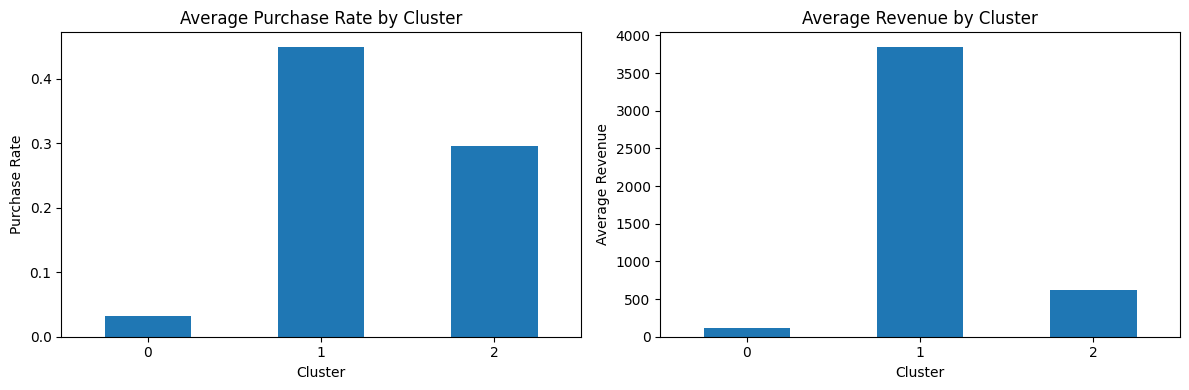

         customers  purchase_rate  total_revenue
cluster                                         
0             3488           0.03         119.49
1             2055           0.45        3847.71
2             2899           0.30         618.26


In [38]:

import matplotlib.pyplot as plt

cluster_summary = customer_features.groupby("cluster").agg(
    customers=("customer_id", "count"),
    purchase_rate=("purchase_rate", "mean"),
    total_revenue=("total_revenue", "mean")
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

cluster_summary["purchase_rate"].plot(
    kind="bar", ax=axes[0], title="Average Purchase Rate by Cluster"
)
axes[0].set_xlabel("Cluster")
axes[0].set_ylabel("Purchase Rate")
axes[0].tick_params(axis="x", rotation=0)

cluster_summary["total_revenue"].plot(
    kind="bar", ax=axes[1], title="Average Revenue by Cluster"
)
axes[1].set_xlabel("Cluster")
axes[1].set_ylabel("Average Revenue")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

print(cluster_summary.round(2))



## Model Comparison

I compared the regression, classification, and clustering models using their evaluation metrics to understand how well each one performed.


In [39]:

import pandas as pd

model_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Tuned Ridge Regression",
        "Tuned Logistic Regression",
        "K-Means Clustering"
    ],
    "Evaluation Metric": [
        "MAE / RMSE / R²",
        "MAE / RMSE / R²",
        "Precision / Recall / F1 / ROC-AUC",
        "Inertia / Silhouette Score"
    ],
    "Result": [
        "MAE=0.9219, RMSE=1.1415, R²=-0.0829",
        "MAE=0.8970, RMSE=1.1033, R²=-0.0115",
        "Precision=0.3601, Recall=0.9234, F1=0.5181, ROC-AUC=0.7644",
        "K=3, Silhouette Score=0.1216"
    ]
})

display(model_comparison)


,Model,Evaluation Metric,Result
0,Linear Regression,MAE / RMSE / R²,"MAE=0.9219, RMSE=1.1415, R²=-0.0829"
1,Tuned Ridge Regression,MAE / RMSE / R²,"MAE=0.8970, RMSE=1.1033, R²=-0.0115"
2,Tuned Logistic Regression,Precision / Recall / F1 / ROC-AUC,"Precision=0.3601, Recall=0.9234, F1=0.5181, RO..."
3,K-Means Clustering,Inertia / Silhouette Score,"K=3, Silhouette Score=0.1216"



### K-Means Hyperparameter Tuning

I am comparing different K-Means configurations using inertia and silhouette score to check which configuration groups customers better.


In [41]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

results = []

for k in [3, 4, 5, 6]:
    for init_method in ["k-means++", "random"]:
        model = KMeans(
            n_clusters=k,
            init=init_method,
            max_iter=300,
            random_state=42,
            n_init=10
        )

        labels = model.fit_predict(X_scaled)

        results.append({
            "K": k,
            "Initialization": init_method,
            "Inertia": round(model.inertia_, 2),
            "Silhouette Score": round(
                silhouette_score(X_scaled, labels), 4
            )
        })

kmeans_tuning_results = pd.DataFrame(results)
display(
    kmeans_tuning_results.sort_values(
        "Silhouette Score", ascending=False
    ).reset_index(drop=True)
)


,K,Initialization,Inertia,Silhouette Score
0,3,k-means++,60178.54,0.1216
1,3,random,60178.82,0.1216
2,4,random,56251.88,0.1092
3,6,k-means++,50409.29,0.1051
4,6,random,50408.78,0.1048
5,5,random,52728.95,0.1028
6,5,k-means++,52728.98,0.1026
7,4,k-means++,56246.40,0.0860


In [42]:

best_kmeans_config = kmeans_tuning_results.sort_values(
    "Silhouette Score", ascending=False
).iloc[0]

print("Best K-Means configuration:")
print(best_kmeans_config)

print("\nCurrent final model:")
print("K =", 3)
print("Silhouette Score =", round(silhouette_score(
    X_scaled, customer_features["cluster"]
), 4))


Best K-Means configuration:
K                           3
Initialization      k-means++
Inertia              60178.54
Silhouette Score       0.1216
Name: 0, dtype: object

Current final model:
K = 3
Silhouette Score = 0.1216



## Business Insights

- Ridge Regression performed slightly better than Linear Regression, but its negative R² shows that rating prediction needs improvement.
- Logistic Regression achieved a recall of 92.34%, helping identify most potential purchases, although it also produced many false positives.
- K-Means identified three customer groups. Cluster 1 had the highest purchase rate and revenue, while Cluster 0 had very low purchase activity.
- Customers in Cluster 2 frequently added products to their carts, so targeted offers or checkout improvements may help increase conversions.



## Conclusion

In this project, I used Linear Regression and Ridge Regression to predict product ratings, Logistic Regression to predict purchase behavior, and K-Means to segment customers. Ridge Regression gave slightly better results than Linear Regression, while Logistic Regression provided high recall after threshold tuning. K-Means grouped customers into three segments with different purchase patterns. These results can help an e-commerce business understand customer behavior and plan targeted marketing strategies. The models can be improved further by testing additional features and tuning their parameters.
